In [ ]:
!pip install -q "transformers>=4.40.0" "bitsandbytes>=0.46.1" accelerate datasets captum

In [ ]:
import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.manifold import TSNE
from tqdm import tqdm
from enum import Enum
from transformers import AutoTokenizer, AutoModel, BitsAndBytesConfig

In [ ]:
from google.colab import drive, userdata
from huggingface_hub import login

drive.mount('/content/drive')
login(token=userdata.get('HF_TOKEN'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Config

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

# HF token required only for meta-llama/Llama-3.1-8B
HF_TOKEN = ""

MODEL_CONFIGS = {
    "llama3.1-8b": {
        "hf_name": "meta-llama/Llama-3.1-8B",
        "use_4bit": True,
        "needs_token": True,
    },
    "rollama3-8b": {
        "hf_name": "OpenLLM-Ro/RoLlama3-8b-Instruct-4bit",
        "use_4bit": True,
        "needs_token": False,
    },
    "mgpt-1.3b": {
        "hf_name": "ai-forever/mGPT-1.3B-romanian",
        "use_4bit": False,
        "needs_token": False,
    },
    "llmic-3b": {
        "hf_name": "faur-ai/LLMic",
        "use_4bit": True,
        "needs_token": False,
    },
}

MAX_LENGTH       = 256
EMBED_BATCH_SIZE = 16
MLP_HIDDEN_DIM   = 512
MLP_EPOCHS       = 30
MLP_LR           = 1e-3
MLP_WEIGHT_DECAY = 1e-4
MLP_BATCH_SIZE   = 64
RANDOM_SEED      = 42

Device: cuda


## Load LaRoSeDA

In [ ]:
LAROSEDA_DIR = '/content/drive/MyDrive/LaRoSeDA'

def load_laroseda(pos_path, neg_path):
    with open(pos_path, "r", encoding="utf-8") as f:
        pos_data = json.load(f)
    with open(neg_path, "r", encoding="utf-8") as f:
        neg_data = json.load(f)

    samples = []
    for item in pos_data["reviews"]:
        samples.append((item["title"] + " " + item["content"], 1))
    for item in neg_data["reviews"]:
        samples.append((item["title"] + " " + item["content"], 0))
    return samples

samples = load_laroseda(
    f"{LAROSEDA_DIR}/positive_reviews.json",
    f"{LAROSEDA_DIR}/negative_reviews.json",
)
texts  = [s[0] for s in samples]
labels = [s[1] for s in samples]

X_train, X_temp, y_train, y_temp = train_test_split(
    texts, labels, test_size=0.3, stratify=labels, random_state=RANDOM_SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_SEED
)

print(f"Train: {len(X_train)}  Val: {len(X_val)}  Test: {len(X_test)}")

Train: 10500  Val: 2250  Test: 2250


## Dataset & DataLoaders

In [ ]:
class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts  = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return {"text": self.texts[idx], "label": self.labels[idx]}


def make_loaders(*splits, batch_size=EMBED_BATCH_SIZE):
    return tuple(
        DataLoader(TextDataset(x, y), batch_size=batch_size, shuffle=False)
        for x, y in splits
    )

train_loader, val_loader, test_loader = make_loaders(
    (X_train, y_train), (X_val, y_val), (X_test, y_test)
)

## Model loading

In [ ]:
def load_model(model_key):
    cfg   = MODEL_CONFIGS[model_key]
    token = userdata.get('HF_TOKEN') if cfg["needs_token"] else None

    bnb_config = None
    if cfg["use_4bit"]:
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.bfloat16,
            bnb_4bit_use_double_quant=True,
        )

    tokenizer = AutoTokenizer.from_pretrained(cfg["hf_name"], token=token)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "right"

    kwargs = {"token": token, "device_map": "auto"}
    if bnb_config:
        kwargs["quantization_config"] = bnb_config
    else:
        kwargs["torch_dtype"] = torch.float16

    model = AutoModel.from_pretrained(cfg["hf_name"], **kwargs)
    model.eval()
    print(f"Loaded {model_key}  |  hidden size: {model.config.hidden_size}")
    return tokenizer, model


def unload_model(model):
    del model
    gc.collect()
    torch.cuda.empty_cache()

## Pooling strategies & embedding extraction

In [ ]:
class PoolingStrategy(str, Enum):
    LAST    = "last"
    MEAN    = "mean"
    ECHO    = "echo"
    SUMMARY = "summary"

# Romanian summary prompt
SUMMARY_TEMPLATE = "Acest text: {} inseamna intr-un cuvant:"


def prepare_texts(texts, strategy):
    if strategy == PoolingStrategy.ECHO:
        return [t + " " + t for t in texts]
    if strategy == PoolingStrategy.SUMMARY:
        return [SUMMARY_TEMPLATE.format(t) for t in texts]
    return texts


def pool(hidden_states, attention_mask, strategy):
    if strategy == PoolingStrategy.MEAN:
        mask = attention_mask.unsqueeze(-1).float()
        emb  = (hidden_states * mask).sum(1) / mask.sum(1)
    else:
        # last real token for LAST / ECHO / SUMMARY
        lengths = attention_mask.sum(dim=1) - 1
        emb = hidden_states[torch.arange(hidden_states.size(0)), lengths]

    return F.normalize(emb, p=2, dim=1)


@torch.no_grad()
def compute_embeddings(dataloader, tokenizer, model, strategy):
    all_embs   = []
    all_labels = []

    for batch in tqdm(dataloader, desc=f"[{strategy.value}]", leave=False):
        texts = prepare_texts(list(batch["text"]), strategy)

        encoded = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt",
        )
        encoded = {k: v.to(DEVICE) for k, v in encoded.items()}
        output  = model(**encoded)
        emb     = pool(output.last_hidden_state, encoded["attention_mask"], strategy)

        all_embs.append(emb.cpu().float())
        all_labels.extend(batch["label"].tolist())

    return torch.cat(all_embs), torch.tensor(all_labels)

## MLP

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=MLP_HIDDEN_DIM, num_classes=2, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, num_classes),
        )

    def forward(self, x):
        return self.net(x)


def train_mlp(X_train, y_train, X_val, y_val, input_dim):
    mlp     = MLP(input_dim).to(DEVICE)
    opt     = torch.optim.AdamW(mlp.parameters(), lr=MLP_LR, weight_decay=MLP_WEIGHT_DECAY)
    loss_fn = nn.CrossEntropyLoss()

    train_dl = DataLoader(
        TensorDataset(X_train.to(DEVICE), y_train.to(DEVICE)),
        batch_size=MLP_BATCH_SIZE, shuffle=True
    )
    X_val_d  = X_val.to(DEVICE)
    y_val_np = y_val.numpy()

    best_f1, best_state = 0.0, None

    for _ in range(MLP_EPOCHS):
        mlp.train()
        for xb, yb in train_dl:
            opt.zero_grad()
            loss_fn(mlp(xb), yb).backward()
            opt.step()

        mlp.eval()
        with torch.no_grad():
            preds = mlp(X_val_d).argmax(dim=1).cpu().numpy()
        val_f1 = f1_score(y_val_np, preds, average="macro")
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {k: v.clone() for k, v in mlp.state_dict().items()}

    mlp.load_state_dict(best_state)
    return mlp


def evaluate_mlp(mlp, X_test, y_test):
    mlp.eval()
    with torch.no_grad():
        preds = mlp(X_test.to(DEVICE)).argmax(dim=1).cpu().numpy()
    y_np = y_test.numpy()
    return {
        "accuracy": accuracy_score(y_np, preds),
        "macro_f1": f1_score(y_np, preds, average="macro"),
        "report":   classification_report(y_np, preds, target_names=["Negative", "Positive"]),
    }

## Task 1: Model comparison (last-token pooling)

Fix pooling to `last`, vary the model.

In [ ]:
results_exp1 = {}

for model_key in MODEL_CONFIGS:
    print(f"\n{'='*50}")
    print(f"Model: {model_key}")
    tokenizer, llm = load_model(model_key)

    X_tr, y_tr = compute_embeddings(train_loader, tokenizer, llm, PoolingStrategy.LAST)
    X_vl, y_vl = compute_embeddings(val_loader,   tokenizer, llm, PoolingStrategy.LAST)
    X_te, y_te = compute_embeddings(test_loader,  tokenizer, llm, PoolingStrategy.LAST)

    mlp     = train_mlp(X_tr, y_tr, X_vl, y_vl, X_tr.shape[1])
    metrics = evaluate_mlp(mlp, X_te, y_te)
    results_exp1[model_key] = metrics

    print(f"  Accuracy : {metrics['accuracy']:.4f}")
    print(f"  Macro F1 : {metrics['macro_f1']:.4f}")
    print(metrics["report"])

    unload_model(llm)


Model: llama3.1-8b


config.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

...

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

LlamaModel LOAD REPORT from: faur-ai/LLMic
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded llmic-3b  |  hidden size: 2560


  Accuracy : 0.9689
  Macro F1 : 0.9689
              precision    recall  f1-score   support

    Negative       0.98      0.96      0.97      1125
    Positive       0.96      0.98      0.97      1125

    accuracy                           0.97      2250
   macro avg       0.97      0.97      0.97      2250
weighted avg       0.97      0.97      0.97      2250



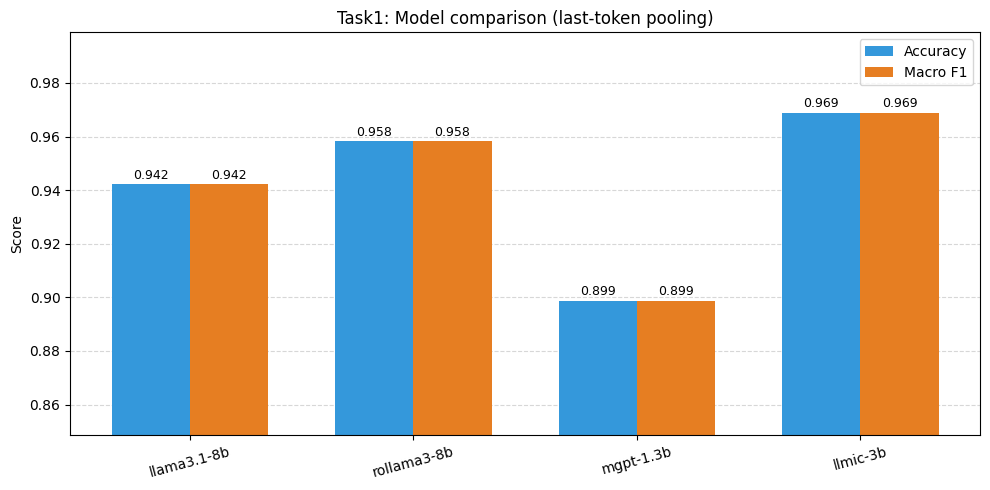

In [ ]:
model_names = list(results_exp1.keys())
accs = [results_exp1[m]["accuracy"] for m in model_names]
f1s  = [results_exp1[m]["macro_f1"]  for m in model_names]

x = np.arange(len(model_names))
w = 0.35

all_scores = accs + f1s
y_min = max(0, min(all_scores) - 0.05)
y_max = min(1, max(all_scores) + 0.03)

fig, ax = plt.subplots(figsize=(10, 5))
bars_acc = ax.bar(x - w/2, accs, w, label="Accuracy", color="#3498db")
bars_f1  = ax.bar(x + w/2, f1s,  w, label="Macro F1", color="#e67e22")

for bar in bars_acc:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.001,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)
for bar in bars_f1:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.001,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15)
ax.set_ylim(y_min, y_max)
ax.set_ylabel("Score")
ax.set_title("Task1: Model comparison (last-token pooling)")
ax.legend()
ax.yaxis.grid(True, linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("task1_model_comparison.png", dpi=150)
plt.show()

## Task 2: Pooling strategy comparison

All 4 models x all 4 pooling strategies.

In [ ]:
STRATEGIES = [
    PoolingStrategy.LAST,
    PoolingStrategy.MEAN,
    PoolingStrategy.ECHO,
    PoolingStrategy.SUMMARY,
]

results_exp2 = {}  # (model_key, strategy.value) -> metrics

for model_key in MODEL_CONFIGS:
    print(f"\n{'='*50}")
    print(f"Model: {model_key}")
    tokenizer, llm = load_model(model_key)

    for strategy in STRATEGIES:
        print(f"  Strategy: {strategy.value}")
        X_tr, y_tr = compute_embeddings(train_loader, tokenizer, llm, strategy)
        X_vl, y_vl = compute_embeddings(val_loader,   tokenizer, llm, strategy)
        X_te, y_te = compute_embeddings(test_loader,  tokenizer, llm, strategy)

        mlp     = train_mlp(X_tr, y_tr, X_vl, y_vl, X_tr.shape[1])
        metrics = evaluate_mlp(mlp, X_te, y_te)
        results_exp2[(model_key, strategy.value)] = metrics

        print(f"    Accuracy: {metrics['accuracy']:.4f}  Macro F1: {metrics['macro_f1']:.4f}")

    unload_model(llm)


Model: llama3.1-8b


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

LlamaModel LOAD REPORT from: meta-llama/Llama-3.1-8B
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded llama3.1-8b  |  hidden size: 4096
  Strategy: last


    Accuracy: 0.9480  Macro F1: 0.9480
  Strategy: mean


...

Loaded llmic-3b  |  hidden size: 2560
  Strategy: last


    Accuracy: 0.9658  Macro F1: 0.9658
  Strategy: mean


    Accuracy: 0.9680  Macro F1: 0.9680
  Strategy: echo


    Accuracy: 0.9702  Macro F1: 0.9702
  Strategy: summary


    Accuracy: 0.9711  Macro F1: 0.9711


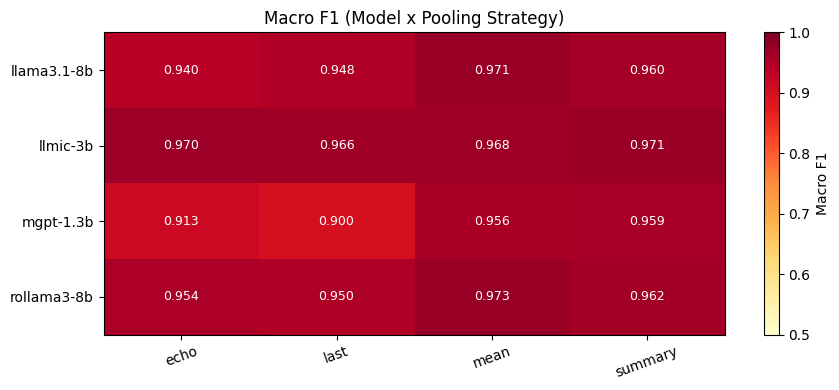


Full results ranked by Macro F1:
      model strategy  accuracy  macro_f1
rollama3-8b     mean  0.973333  0.973333
llama3.1-8b     mean  0.971111  0.971109
   llmic-3b  summary  0.971111  0.971109
   llmic-3b     echo  0.970222  0.970222
   llmic-3b     mean  0.968000  0.967997
   llmic-3b     last  0.965778  0.965769
rollama3-8b  summary  0.961778  0.961777
llama3.1-8b  summary  0.960000  0.959998
  mgpt-1.3b  summary  0.958667  0.958666
  mgpt-1.3b     mean  0.956000  0.956000
rollama3-8b     echo  0.953778  0.953776
rollama3-8b     last  0.949778  0.949773
llama3.1-8b     last  0.948000  0.947991
llama3.1-8b     echo  0.939556  0.939556
  mgpt-1.3b     echo  0.913333  0.913317
  mgpt-1.3b     last  0.899556  0.899552


In [ ]:
rows = []
for (model_key, strat), m in results_exp2.items():
    rows.append({
        "model":    model_key,
        "strategy": strat,
        "accuracy": m["accuracy"],
        "macro_f1": m["macro_f1"],
    })
df2    = pd.DataFrame(rows)
pivot  = df2.pivot(index="model", columns="strategy", values="macro_f1")

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(pivot.values, cmap="YlOrRd", aspect="auto", vmin=0.5, vmax=1.0)
plt.colorbar(im, ax=ax, label="Macro F1")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=20)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center", fontsize=9,
                color="black" if pivot.values[i, j] < 0.85 else "white")
ax.set_title("Macro F1 (Model x Pooling Strategy)")
plt.tight_layout()
plt.savefig("task2_heatmap.png", dpi=150)
plt.show()

print("\nFull results ranked by Macro F1:")
print(df2.sort_values("macro_f1", ascending=False).to_string(index=False))

## Visualizations

In [ ]:
best_key = max(results_exp2, key=lambda k: results_exp2[k]["macro_f1"])
best_model_key, best_strategy_val = best_key
print(f"Best combo: {best_model_key} / {best_strategy_val}  "
      f"Macro F1={results_exp2[best_key]['macro_f1']:.4f}")

full_loader = DataLoader(TextDataset(texts, labels), batch_size=EMBED_BATCH_SIZE, shuffle=False)

tokenizer, llm = load_model(best_model_key)

tsne_data = {}
for strategy in STRATEGIES:
    embs, lbls = compute_embeddings(full_loader, tokenizer, llm, strategy)
    tsne_data[strategy.value] = (embs.numpy(), lbls.numpy())
    print(f"  {strategy.value}: {embs.shape}")

unload_model(llm)

Best combo: rollama3-8b / mean  Macro F1=0.9733


/usr/local/lib/python3.12/dist-packages/transformers/quantizers/auto.py:246: UserWarning: You passed `quantization_config` or equivalent parameters to `from_pretrained` but the model you're loading already has a `quantization_config` attribute. The `quantization_config` from the model will be used.
  warnings.warn(warning_msg)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

LlamaModel LOAD REPORT from: OpenLLM-Ro/RoLlama3-8b-Instruct-4bit
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded rollama3-8b  |  hidden size: 4096


  last: torch.Size([15000, 4096])


  mean: torch.Size([15000, 4096])


  echo: torch.Size([15000, 4096])


  summary: torch.Size([15000, 4096])


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


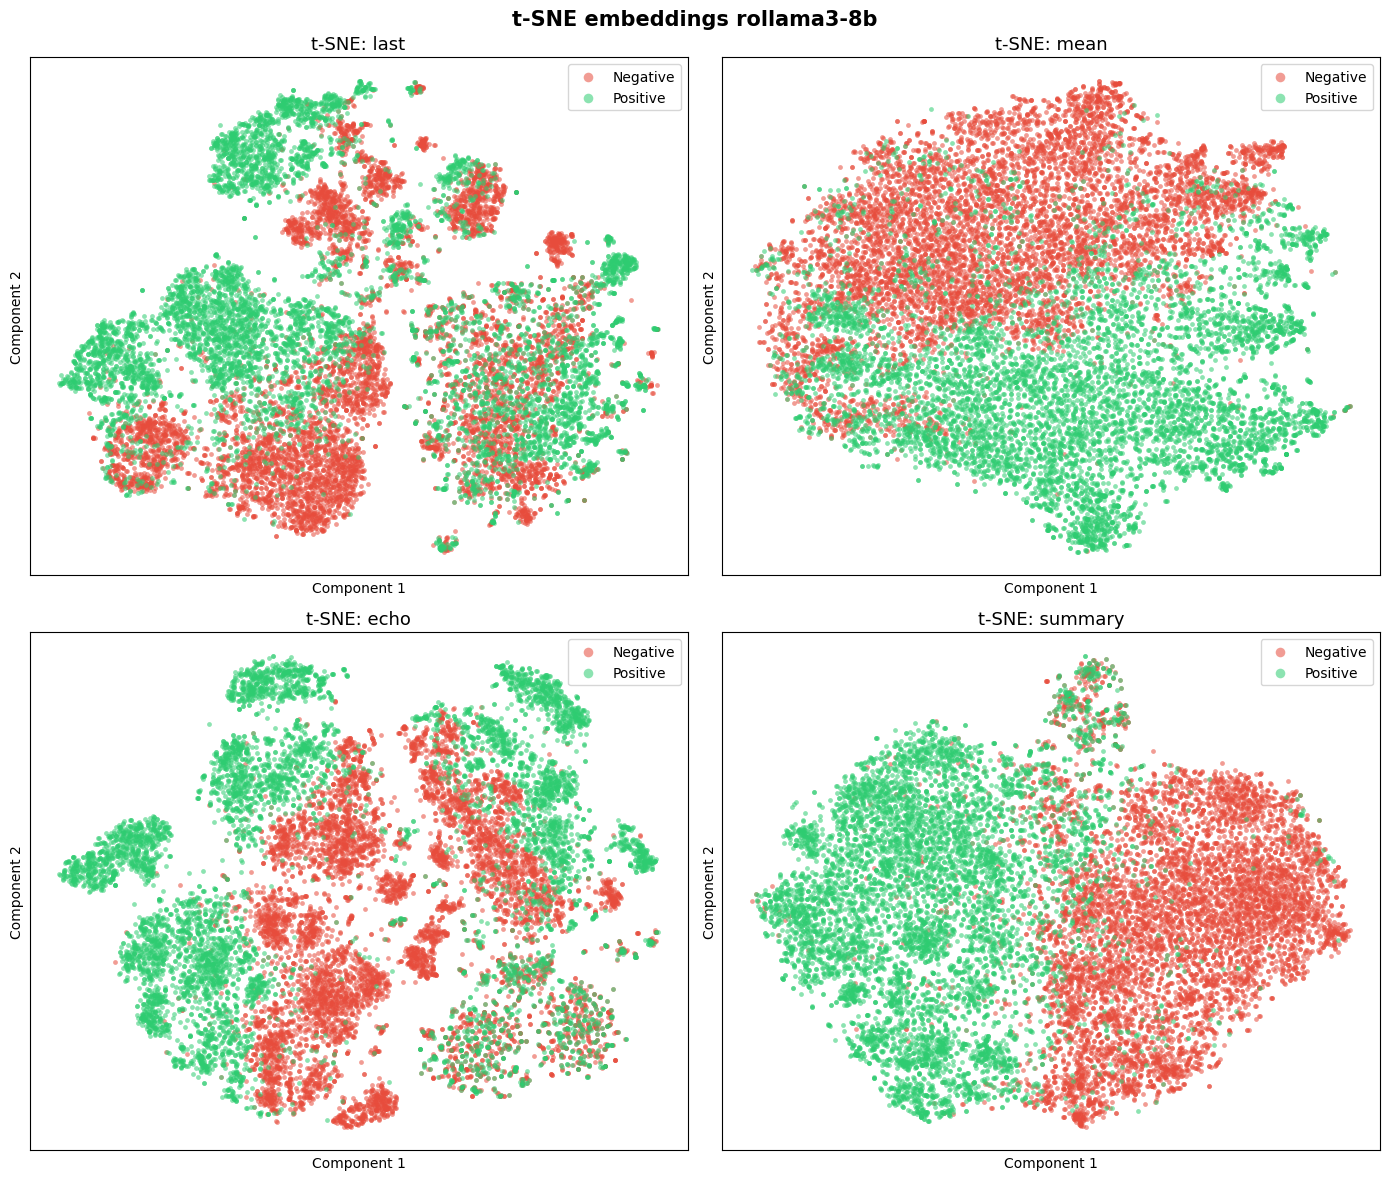

In [ ]:
COLORS      = ["#e74c3c", "#2ecc71"]
CLASS_NAMES = ["Negative", "Positive"]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, strategy in zip(axes, STRATEGIES):
    embs, lbls = tsne_data[strategy.value]

    proj = TSNE(
        n_components=2, perplexity=30, n_iter=1000, random_state=RANDOM_SEED
    ).fit_transform(embs)

    for cls in [0, 1]:
        mask = lbls == cls
        ax.scatter(
            proj[mask, 0], proj[mask, 1],
            c=COLORS[cls], label=CLASS_NAMES[cls],
            alpha=0.55, s=12, linewidths=0
        )

    ax.set_title(f"t-SNE: {strategy.value}", fontsize=13)
    ax.legend(markerscale=2)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(f"t-SNE embeddings {best_model_key}", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("tsne_best_model.png", dpi=150)
plt.show()

/usr/local/lib/python3.12/dist-packages/transformers/quantizers/auto.py:246: UserWarning: You passed `quantization_config` or equivalent parameters to `from_pretrained` but the model you're loading already has a `quantization_config` attribute. The `quantization_config` from the model will be used.
  warnings.warn(warning_msg)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

LlamaModel LOAD REPORT from: OpenLLM-Ro/RoLlama3-8b-Instruct-4bit
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded rollama3-8b  |  hidden size: 4096


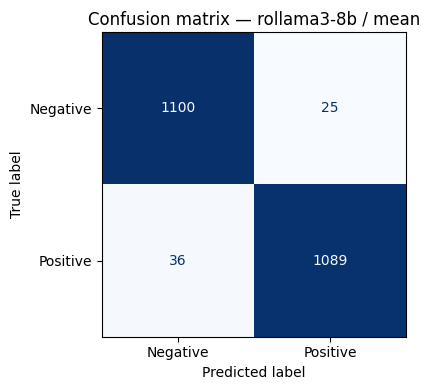

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_key = max(results_exp2, key=lambda k: results_exp2[k]["macro_f1"])
best_model_key, best_strategy_val = best_key
best_strategy = PoolingStrategy(best_strategy_val)

tokenizer, llm = load_model(best_model_key)
X_tr, y_tr = compute_embeddings(train_loader, tokenizer, llm, best_strategy)
X_vl, y_vl = compute_embeddings(val_loader,   tokenizer, llm, best_strategy)
X_te, y_te = compute_embeddings(test_loader,  tokenizer, llm, best_strategy)

best_mlp = train_mlp(X_tr, y_tr, X_vl, y_vl, X_tr.shape[1])
unload_model(llm)

best_mlp.eval()
with torch.no_grad():
    preds = best_mlp(X_te.to(DEVICE)).argmax(dim=1).cpu().numpy()

cm = confusion_matrix(y_te.numpy(), preds)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(
    ax=ax, colorbar=False, cmap="Blues"
)
ax.set_title(f"Confusion matrix — {best_model_key} / {best_strategy_val}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
tokenizer, llm = load_model("rollama3-8b")

X_tr, y_tr = compute_embeddings(train_loader, tokenizer, llm, PoolingStrategy.MEAN)
X_vl, y_vl = compute_embeddings(val_loader,   tokenizer, llm, PoolingStrategy.MEAN)
X_te, y_te = compute_embeddings(test_loader,  tokenizer, llm, PoolingStrategy.MEAN)

unload_model(llm)

# save so this never happens again
torch.save({"X_tr": X_tr, "y_tr": y_tr, "X_vl": X_vl, "y_vl": y_vl,
            "X_te": X_te, "y_te": y_te},
           "/content/drive/MyDrive/best_embeddings.pt")

best_mlp = train_mlp(X_tr, y_tr, X_vl, y_vl, X_tr.shape[1])

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

LlamaModel LOAD REPORT from: OpenLLM-Ro/RoLlama3-8b-Instruct-4bit
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded rollama3-8b  |  hidden size: 4096


In [ ]:
best_model_key    = "rollama3-8b"
best_strategy_val = "mean"
best_strategy     = PoolingStrategy(best_strategy_val)

In [ ]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)
cfg   = MODEL_CONFIGS[best_model_key]
token = userdata.get("HF_TOKEN") if cfg["needs_token"] else None

tokenizer_ig = AutoTokenizer.from_pretrained(cfg["hf_name"], token=token)
if tokenizer_ig.pad_token is None:
    tokenizer_ig.pad_token = tokenizer_ig.eos_token
tokenizer_ig.padding_side = "right"

llm_ig = AutoModel.from_pretrained(
    cfg["hf_name"], token=token,
    quantization_config=bnb_config,
    device_map="auto"
)
llm_ig.eval()
print(f"Free VRAM: {torch.cuda.mem_get_info()[0] / 1024**3:.2f} GB")

/usr/local/lib/python3.12/dist-packages/transformers/quantizers/auto.py:246: UserWarning: You passed `quantization_config` or equivalent parameters to `from_pretrained` but the model you're loading already has a `quantization_config` attribute. The `quantization_config` from the model will be used.
  warnings.warn(warning_msg)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

LlamaModel LOAD REPORT from: OpenLLM-Ro/RoLlama3-8b-Instruct-4bit
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Free VRAM: 34.59 GB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

LlamaModel LOAD REPORT from: OpenLLM-Ro/RoLlama3-8b-Instruct-4bit
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


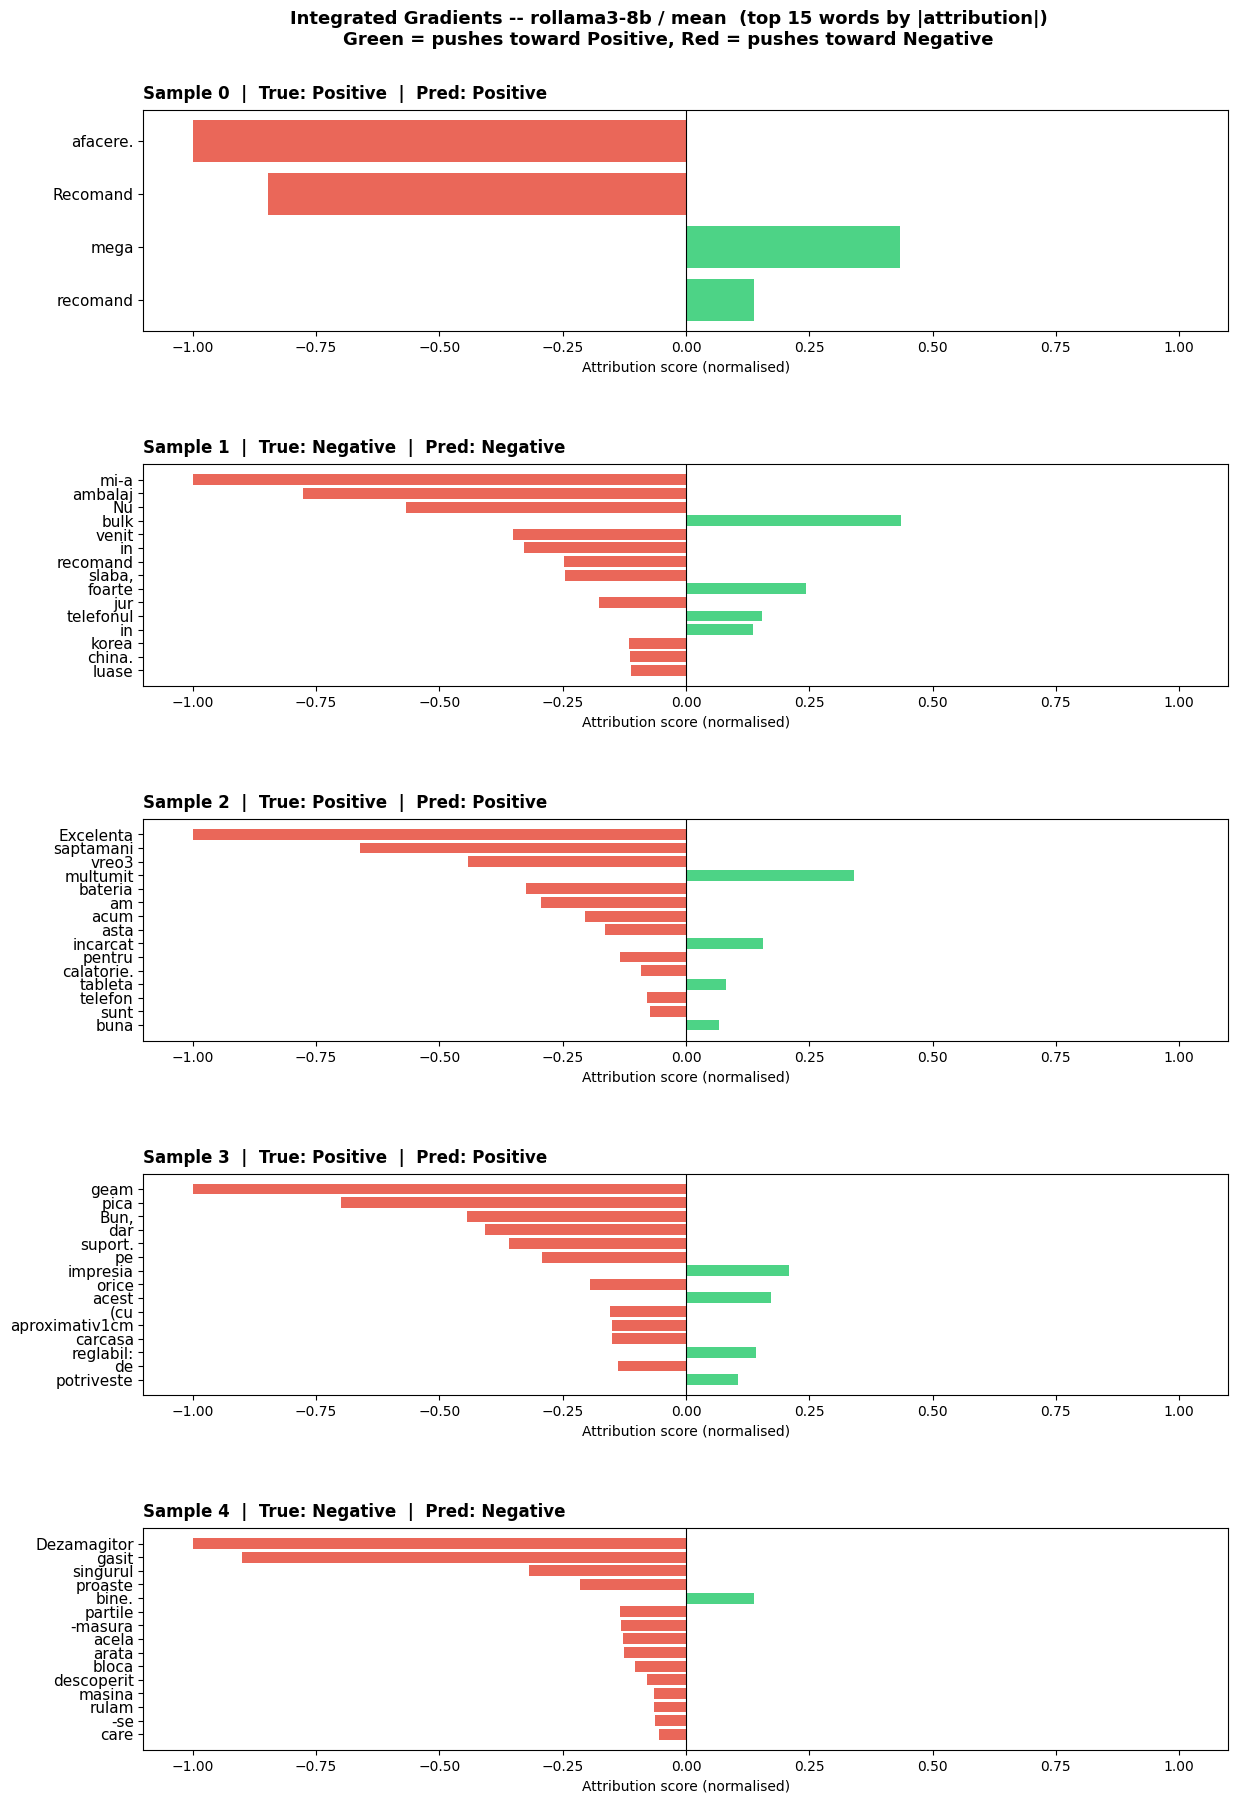

In [ ]:
from captum.attr import IntegratedGradients

cfg = MODEL_CONFIGS[best_model_key]
token = userdata.get("HF_TOKEN") if cfg["needs_token"] else None

tokenizer_ig = AutoTokenizer.from_pretrained(cfg["hf_name"], token=token)
if tokenizer_ig.pad_token is None:
    tokenizer_ig.pad_token = tokenizer_ig.eos_token
tokenizer_ig.padding_side = "right"

llm_ig = AutoModel.from_pretrained(
    cfg["hf_name"], token=token, torch_dtype=torch.float16, device_map="auto"
)
llm_ig.eval()

embed_fn = llm_ig.get_input_embeddings()


def merge_subword_attributions(tokens, scores):
    words, word_scores = [], []
    current_word, current_score = "", 0.0
    for tok, score in zip(tokens, scores):
        is_start = tok.startswith("▁") or tok.startswith("Ġ")
        clean    = tok.replace("▁", "").replace("Ġ", "").strip()
        if not clean or tok in ("<0x0A>",):
            continue
        if is_start and current_word:
            words.append(current_word)
            word_scores.append(current_score)
            current_word  = clean
            current_score = score
        elif is_start:
            current_word  = clean
            current_score = score
        else:
            current_word  += clean
            current_score += score
    if current_word:
        words.append(current_word)
        word_scores.append(current_score)
    return words, np.array(word_scores)


def forward_from_embeds(input_embeds, attention_mask):
    batch_size = input_embeds.shape[0]
    mask = attention_mask.expand(batch_size, -1)
    output = llm_ig(inputs_embeds=input_embeds.to(llm_ig.dtype), attention_mask=mask)
    emb = pool(output.last_hidden_state, mask, best_strategy).float()
    return best_mlp(emb)[:, 1]


ig = IntegratedGradients(forward_from_embeds)

SAMPLE_INDICES = [0, 1, 2, 3, 4]
CLASS_NAMES    = ["Negative", "Positive"]
TOP_K_TOKENS   = 15

fig, axes = plt.subplots(len(SAMPLE_INDICES), 1, figsize=(14, 4 * len(SAMPLE_INDICES)))
fig.suptitle(
    f"Integrated Gradients -- {best_model_key} / {best_strategy_val}  "
    f"(top {TOP_K_TOKENS} words by |attribution|)\n"
    "Green = pushes toward Positive, Red = pushes toward Negative",
    fontsize=13, fontweight="bold"
)
fig.subplots_adjust(top=0.93, hspace=0.6)

for ax, idx in zip(axes, SAMPLE_INDICES):
    text  = prepare_texts([X_test[idx]], best_strategy)[0]
    label = y_test[idx]

    encoded = tokenizer_ig(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
    )
    input_ids      = encoded["input_ids"].to(DEVICE)
    attention_mask = encoded["attention_mask"].to(DEVICE)

    with torch.no_grad():
        input_embeds = embed_fn(input_ids).float()
    baseline_embeds = torch.zeros_like(input_embeds)

    attributions = ig.attribute(
        inputs=input_embeds,
        baselines=baseline_embeds,
        additional_forward_args=(attention_mask,),
        n_steps=20,
    )

    token_scores = attributions.squeeze(0).sum(dim=-1).cpu().numpy()
    raw_tokens   = tokenizer_ig.convert_ids_to_tokens(input_ids[0].cpu())

    special = {tokenizer_ig.bos_token, tokenizer_ig.eos_token, tokenizer_ig.pad_token}
    filtered_tokens = [t for t in raw_tokens if t not in special]
    filtered_scores = [s for t, s in zip(raw_tokens, token_scores) if t not in special]

    words, word_scores = merge_subword_attributions(filtered_tokens, filtered_scores)

    top_idx    = np.argsort(np.abs(word_scores))[-TOP_K_TOKENS:][::-1]
    top_words  = [words[i] for i in top_idx]
    top_scores = word_scores[top_idx]
    top_scores_norm = top_scores / (np.abs(top_scores).max() + 1e-8)

    colors = ["#e74c3c" if s < 0 else "#2ecc71" for s in top_scores_norm]

    ax.barh(range(len(top_words)), top_scores_norm, color=colors, alpha=0.85)
    ax.set_yticks(range(len(top_words)))
    ax.set_yticklabels(top_words, fontsize=11)
    ax.set_xlim(-1.1, 1.1)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Attribution score (normalised)")
    ax.invert_yaxis()

    with torch.no_grad():
        pred_class = best_mlp(
            pool(
                llm_ig(inputs_embeds=embed_fn(input_ids).to(llm_ig.dtype),
                       attention_mask=attention_mask).last_hidden_state,
                attention_mask, best_strategy
            ).float()
        ).argmax(dim=1).item()

    ax.set_title(
        f"Sample {idx}  |  True: {CLASS_NAMES[label]}  |  Pred: {CLASS_NAMES[pred_class]}",
        fontsize=12, fontweight="bold", loc="left", pad=8
    )

plt.savefig("integrated_gradients.png", dpi=150, bbox_inches="tight")
plt.show()

unload_model(llm_ig)

In [ ]:
# clear everything from exp2
import gc
gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()
print(f"Free VRAM: {(torch.cuda.mem_get_info()[0] / 1024**3):.2f} GB")

Free VRAM: 38.89 GB


In [ ]:
try:
    del llm
except NameError:
    pass
gc.collect()
torch.cuda.empty_cache()

In [ ]:
unload_model(llm_ig)

In [ ]:
import gc

# delete all tensors and modules from global scope
for name in list(globals().keys()):
    obj = globals()[name]
    if isinstance(obj, (torch.nn.Module, torch.Tensor)):
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()
print(f"Free VRAM: {torch.cuda.mem_get_info()[0] / 1024**3:.2f} GB")

Free VRAM: 2.79 GB
